# Text classification with recurrent neural networks

Recurrent neural networks (RNNs) are appropriate for handling sequential data, where each point depends on the previous one(s). This is the case, e.g., for time series (audio/speech signals, financial data...), but also videos (time sequence of images), or text, which we consider here.
 
In this lab, we use RNNs for a binary classification task, which is hate speech detection from tweets. We introduce the global pipeline for preprocessing text data, as well as the basics of RNNs, and we implement a simple classification model.

## Before we begin on DCE

### Starting Jupyter on DCE (using VSCode)

The easiest is to use VSCode with the jupyter and python extensions for this lab.

First use this in the terminal to connect to a node with the reservation code:

`srun --reservation=asdl_part21 --pty bash`

Or outside a reservation:

`srun -p cpu_inter -t 2:00:00 --pty bash`

I made you a handy script to automate starting jupyter, just run this inside your allocation:

`/mounts/datasets/tps/ia2vr/TP1/start_lab_jupyter.sh`

At the end, in between the ====================, it will give you the URL you need to copy.

Then in the top right of VSCode, Select Kernel > Existing Jupyter Server > Enter URL > The URL you copied should be pasted > Confirm the name > Select the one and only kernel available (should be the venv the script created)

Now let's just check that your kernel works:

In [1]:
1+1

2

**If you need access to your terminal again, you can put jupyterlab in the background with Ctrl+Z, followed by the `bg` command!**

### Additional packages

**Note**: The first time you run this notebook this lab session, please uncomment the first cell below to install the required packages (this can take several minutes) and to download the NLP pipeline for English using spacy.

In [2]:
%pip install spacy
import spacy.cli
spacy.cli.download("en_core_web_sm")

Note: you may need to restart the kernel to use updated packages.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 37.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


**As instructed, restart your kernel!** (the restart button is up top in the toolbar)

Then execute this cell to load everything. You shouldn't get any errors if all went well.

In [3]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, random_split
import copy
import matplotlib.pyplot as plt
import datasets
import spacy
from collections import Counter

We will use my folder for convenience, so you don't all have to download the data again.
 
If it doesn't work, change this path to something like `$TMPDIR/datasets`

In [4]:
# Main dataset path - If needed, you can change it HERE but NOWHERE ELSE in the notebook!
data_dir = '/mounts/datasets/tps/ia2vr/TP1/datasets/'

### Dataset

We use the [Tweets Hate Speech](https://huggingface.co/datasets/tweets-hate-speech-detection/tweets_hate_speech_detection) dataset, which contains a collections of tweets, along with a label (0= no hate speech; 1=hate speech). It can be directly downloaded via the `datasets` package.

In [5]:
# Load (eventually download) the dataset
dataset = datasets.load_dataset("tweets-hate-speech-detection/tweets_hate_speech_detection", cache_dir=data_dir)["train"]
print(f"Dataset size: {len(dataset)}")

# Print one example: it has two keys 'tweet' and 'label', corresponding to the text and corresponding label
print(dataset[0])

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/2.07M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/31962 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/17197 [00:00<?, ? examples/s]

Dataset size: 31962
{'label': 0, 'tweet': '@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction.   #run'}


## Preprocessing text data

### Tokenizers

The first step to prepare our data is to define *tokenizers*, that is, how a string is transformed into a sequence of words (or *tokens*). For instance, "Welcome to the U.S.A.!" should be transformed into \["Welcome", "to", "the", "U.S.A.", "!"\]. These are called tokens in the general case because "!" is not a word.

To perform tokenization, we rely on language-specific rules, in order to preserve some particular structure: for instance, with a naïve approach, "U.S.A." would be split into 6 tokens \["U", ".", "S', ".", "A", "."\], but we want to consider it as a single token.

In [6]:
# load the English specific NLP pipeline
en_nlp = spacy.load('en_core_web_sm')

# define English tokenizer
def tokenize_en(text):
    return [tok.text for tok in en_nlp.tokenizer(text)]

# check on an example
print('Welcome to the U.S.A!')
print(tokenize_en('Welcome to the U.S.A.!'))

Welcome to the U.S.A!
['Welcome', 'to', 'the', 'U.S.A.', '!']


In [7]:
# a more complete function that also remove caps,and add special tokens corresponding to the start/end of a sentence
def tokenize_example(example, en_nlp, lower=True, sos_token='<sos>', eos_token='<eos>'):
    tokens = [token.text for token in en_nlp.tokenizer(example["tweet"])]
    if lower:
        tokens = [token.lower() for token in tokens]
    tokens = [sos_token] + tokens + [eos_token]
    return {"tokens": tokens}

sos_token = "<sos>"
eos_token = "<eos>"
print(tokenize_example(dataset[0], en_nlp, sos_token, eos_token))

{'tokens': ['<eos>', '@user', 'when', 'a', 'father', 'is', 'dysfunctional', 'and', 'is', 'so', 'selfish', 'he', 'drags', 'his', 'kids', 'into', 'his', 'dysfunction', '.', '  ', '#', 'run', '<eos>']}


In [8]:
# Tokenize the whole dataset (it will add a 'tokens' entry to each data sample)
dataset = dataset.map(tokenize_example, fn_kwargs={"en_nlp": en_nlp})

Map:   0%|          | 0/31962 [00:00<?, ? examples/s]

### Vocabulary

Next, we need to build a *vocabulary* for the  language. A vocabulary associates each token to an integer index (e.g., "Welcome"=0, "to"=1, "the"=2, etc.) which then allows us to manipulate text data with neural networks (since these can only operate on numerical data, not on strings/characters). Functions to build a vocabulary are usually incorporated in most NLP-related packages / librairies, but here we provide one simple class that allows to do everything we need.

In [9]:
class Vocab:
    def __init__(
        self,
        texts,
        max_vocab=None,
        min_freq=2,
        special_tokens=['<unk>', '<pad>', '<sos>', '<eos>']
    ):
        self.special_tokens = special_tokens
        self.max_vocab = max_vocab
        if self.max_vocab:
            self.max_vocab =- 2 # acount for <unk> and <pad>
        self.min_freq = min_freq
        self.special_tokens = special_tokens
        # Build the dictionary (word2id) and list to revert it (id2word)
        self.word2id = self._build_word2id(texts)
        self.id2word = list(self.word2id.keys())
        
    # Base function to call word2id, acounting for unknown words
    def apply_word2id(self, key, unk_id=0):
        return self.word2id[key] if key in self.id2word else unk_id

    # Function to call word2id and id2word with lists of entries
    def lookup_word2id(self, keys, unk_id=0):
        return [self.apply_word2id(x, unk_id) for x in keys]
        
    def lookup_id2word(self, xs):
        return [self.id2word[x] for x in xs]
        
    def __len__(self):
        return len(self.word2id)

    def _build_word2id(self, texts):

        # Create the word counter
        wc = Counter()
        for doc in texts:
            for word in doc:
                wc[word] += 1
                
        # Initialize the dictinonary with special tokens
        word2id = {}
        for i, word in enumerate(self.special_tokens):
            word2id[word] = i
    
        # iterate over the words to build the dict
        for word, count in wc.most_common(self.max_vocab):
            if count < self.min_freq: break
            if word in self.special_tokens: continue
            wid = len(word2id)
            word2id[word] = wid
    
        return word2id

In [10]:
# Instanciate the vocabulary
en_vocab = Vocab(dataset["tokens"], min_freq=2, special_tokens=['<unk>', '<pad>', '<sos>', '<eos>'])

# The vocabulary has a special __len__ methods used as followed:
print('Number of tokens in the vocabulary:', len(en_vocab))

Number of tokens in the vocabulary: 16467


In [11]:
# Display some tokens
print('First tokens in the vocabulary:', en_vocab.id2word[:15])
print(en_vocab.id2word[431])
print(en_vocab.id2word[2000])

First tokens in the vocabulary: ['<unk>', '<pad>', '<sos>', '<eos>', '#', '  ', '@user', ' ', '!', '.', 'the', 'to', 'i', 'a', ',']
london
moved


In [12]:
# Transform a word/token into an integer
print(en_vocab.apply_word2id('london'))

# Getting the index of a token that is not in the vocabulary returns 0 (by default), which corresponds to the unknown ('<unk>') token
print(en_vocab.apply_word2id('notinvocabulary'))

431
0


In [13]:
# Handle multiple entries using the lookup methods:
print(en_vocab.lookup_word2id(['dark', 'scoopwhoopnews', 'needed', 'london']))
print(en_vocab.lookup_id2word([989, 8630, 986, 431]))

[989, 8630, 986, 431]
['dark', 'scoopwhoopnews', 'needed', 'london']


### Numericalization

We can now perform numericalization, which is the process of transforming each tokenized sentence in the dataset into a list of indices. As a result, we now have a dataset of fully numerical data.

In [14]:
def numericalize_example(example, vocab, unk_id=0):
    en_ids = vocab.lookup_word2id(example["tokens"], unk_id=unk_id)
    return {"en_ids": en_ids}

print(numericalize_example(dataset[0], en_vocab))

{'en_ids': [2, 6, 55, 13, 102, 20, 0, 17, 20, 38, 3410, 99, 6626, 120, 290, 291, 120, 8073, 9, 5, 4, 510, 3]}


In [15]:
# Numericalize the whole dataset (it will add a 'en_ids' entry to each data sample)
dataset = dataset.map(numericalize_example, fn_kwargs={"vocab": en_vocab})

Map:   0%|          | 0/31962 [00:00<?, ? examples/s]

In [16]:
# We also need to convert 'en_ids' to torch tensors (as they are currently integers)
dataset = dataset.with_format(type="torch", columns=["en_ids"], output_all_columns=True)

### Dealing with an imbalanced dataset

In [17]:
# TO DO: Compute and display the proportion of positive samples in the dataset (= samples whose label is 1)
# Proportion of positive samples (label == 1) in the full dataset
labels = dataset["label"]
num_pos = sum(labels)
num_total = len(labels)
prop_pos = num_pos / num_total
print(f"Positive samples: {num_pos}/{num_total} = {prop_pos:.4f} ({prop_pos*100:.2f}%)")

Positive samples: 2242/31962 = 0.0701 (7.01%)


As computed above, there are roughly 7% tweets containing hate speech (label=1) and 93% tweets that do not contain hate speech (label=0). Such a dataset is said to be *imbalanced*, thus we cannot use it as such, otherwise it will cause issues at training and inference. Indeed, a naive approach where the network would set all outputs at 0 would yield a 93% accuracy, but would be completely useless in practice. A simple way to address this issue is to take a subset of the dataset, such that both classes are equally represented.

<span style="color:red">**Exercise 1**</span> Get a balanced subset of the dataset
- Get the list of indices of samples whose label is 1 (=`ind_pos`) and 0 (=`ind_neg`)
- Take the first 500 positive indices, and the same negative indices
- Take a subset of the dataset corresponding to these indices (use the `Subset` function), yielding `dataset_balanced`.

In [18]:
# Exercise 1: build a balanced subset (500 positives + 500 negatives)
labels = dataset["label"]
ind_pos = [i for i, y in enumerate(labels) if int(y) == 1]
ind_neg = [i for i, y in enumerate(labels) if int(y) == 0]

# 500 from each class
sel_idx = ind_pos[:500] + ind_neg[:500]
dataset_balanced = Subset(dataset, sel_idx)

print(f"Balanced subset size: {len(dataset_balanced)}")
print(f"Positive samples={len(ind_pos[:500])}, Negative samples={len(ind_neg[:500])}")

Balanced subset size: 1000
Positive samples=500, Negative samples=500


In [19]:
# Split into training, validation, and test subsets
train_data, valid_data, test_data = random_split(dataset_balanced, [800, 100, 100], generator=torch.manual_seed(0))

In [20]:
# TO DO: Display the proportion of positive samples in the train, validation, and test sets

# Proportion of positives in train/valid/test

def pos_counts(subset):
    labels = [int(subset[i]["label"]) for i in range(len(subset))]
    return sum(labels), len(labels)

for name, split in [("train", train_data), ("valid", valid_data), ("test", test_data)]:
    num_pos, num_total = pos_counts(split)
    print(f"{name}: {num_pos}/{num_total} = {num_pos/num_total:.4f} ({(num_pos/num_total)*100:.2f}%)")

train: 406/800 = 0.5075 (50.75%)
valid: 46/100 = 0.4600 (46.00%)
test: 48/100 = 0.4800 (48.00%)


In [21]:
def pos_counts(subset):
    labels = [int(subset[i]["label"]) for i in range(len(subset))]
    return sum(labels), len(labels)

for name, split in [("train", train_data), ("valid", valid_data), ("test", test_data)]:
    num_pos, num_total = pos_counts(split)
    print(f"{name}: {num_pos}/{num_total} = {num_pos/num_total:.4f} ({(num_pos/num_total)*100:.2f}%)")

train: 406/800 = 0.5075 (50.75%)
valid: 46/100 = 0.4600 (46.00%)
test: 48/100 = 0.4800 (48.00%)


### Dataloader

The final step is to build a `Dataloader` to assemble our data samples into batches. Since data samples are sentences of different lengths in general, there is some *padding* needed to assemble them into consistent batches. As a result, we need to define a specific *collate function* for the dataloader (=i.e., the way data samples are assembled into batches), that will handle this padding. For simplicity, we provide the collate function below.

In [22]:
def get_collate_fn(pad_index):
    def collate_fn(batch):
        batch_en_ids = [example["en_ids"] for example in batch]
        batch_labels = [torch.tensor([example["label"]]) for example in batch]
        batch_en_ids = nn.utils.rnn.pad_sequence(batch_en_ids, padding_value=pad_index)
        batch_labels = nn.utils.rnn.pad_sequence(batch_labels, padding_value=pad_index)
        batch = {
            "en_ids": batch_en_ids,
            "labels": batch_labels.to(torch.float32).T
        }
        return batch

    return collate_fn

def get_data_loader(dataset, batch_size, shuffle=False, pad_index=1, seed=0):
    collate_fn = get_collate_fn(pad_index)
    data_loader = DataLoader(
        dataset=dataset,
        batch_size=batch_size,
        collate_fn=collate_fn,
        shuffle=shuffle,
        generator=torch.manual_seed(seed)
    )
    return data_loader

# Build dataloaders
batch_size = 32
train_data_loader = get_data_loader(train_data, batch_size, shuffle=True)
valid_data_loader = get_data_loader(valid_data, batch_size)
test_data_loader = get_data_loader(test_data, batch_size)

In [23]:
# Get a sample and display it
example_batch = next(iter(train_data_loader))
print(example_batch)

{'en_ids': tensor([[   2,    2,    2,  ...,    2,    2,    2],
        [   6,    6,    6,  ...,   12, 1523,    4],
        [   6,   23,   12,  ...,   76,  786,  392],
        ...,
        [   1,    1,  987,  ...,    1,    1,    1],
        [   1,    1,    8,  ...,    1,    1,    1],
        [   1,    1,    3,  ...,    1,    1,    1]]), 'labels': tensor([[1.],
        [0.],
        [1.],
        [1.],
        [0.],
        [0.],
        [1.],
        [0.],
        [1.],
        [1.],
        [0.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [0.],
        [1.],
        [1.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.],
        [1.],
        [1.],
        [0.],
        [0.],
        [1.],
        [0.],
        [1.],
        [1.]])}


## Recurrent networks basics

Now that our data is ready, let's see the basic operations used in RNNs: [embedding layers](https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html?highlight=embedding#torch.nn.Embedding), [dropout](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html), and [recurrent layers](https://pytorch.org/docs/stable/nn.html#recurrent-layers).

### Embedding layer

Sentences have been tokenized and tokens have been transformed into integers, depending on their frequency of occurence in the corpus. Therefore, two consecutive integers correspond to tokens that are not necessarily *similar* from a semantic perspective.

For instance, the token "dog" is represented by integer 277. While similar tokens might be spread away (here: animals such as "cat" and "duck" are represented by integers 519 and 3862), the surrounding integers 276 and 278 correspond to un-related tokens ("polar" and "before"). In other words: integers that are close to each other do not correspond to tokens that are similar. This is a problem for NLP applications, where the numerical representation of the data should incorporate this notion of *similarity*.

One way to overcome this issue it to further transform these integers into high-dimensional *embeddings* (or *word vectors*), that will be trained in such a way that similar tokens should have similar embeddings.

<center><a href="https://ruder.io/word-embeddings-1/">
    <img src="https://ruder.io/content/images/size/w2000/2016/04/word_embeddings_colah.png" width="500"></a></center>

Since it's hard to define exactly what *similar* means out of context, embeddings are usually learned / optimized for a certain task. Here, we use an embedding layer to produce these word vectors, and this layer is learned during training along with the rest of the network.

**Note**: many pre-trained word embeddings are available (e.g., [BERT](https://en.wikipedia.org/wiki/BERT_(language_model))) and could be loaded directly. Here, for simplicity we use a shallow `Embedding` layer which will be learnt from scratch.

In [24]:
# Create an embedding layer. We need to specify:
# - the input size, that is, how many words are in the vocabulary
# - the embedding size, that is, how "big" is the word vectors space 
input_size = len(en_vocab)
emb_size = 32
src_emb_layer = nn.Embedding(input_size, emb_size)

# Apply it to the example batch and display it
embedded_batch = src_emb_layer(example_batch['en_ids'])
print(embedded_batch)

# The size of the word vectors for a batch should be [seq_length, batch_size, emb_size]
print(embedded_batch.shape)

tensor([[[-0.8108, -1.1052, -0.7233,  ...,  1.6909, -0.4622,  0.4427],
         [-0.8108, -1.1052, -0.7233,  ...,  1.6909, -0.4622,  0.4427],
         [-0.8108, -1.1052, -0.7233,  ...,  1.6909, -0.4622,  0.4427],
         ...,
         [-0.8108, -1.1052, -0.7233,  ...,  1.6909, -0.4622,  0.4427],
         [-0.8108, -1.1052, -0.7233,  ...,  1.6909, -0.4622,  0.4427],
         [-0.8108, -1.1052, -0.7233,  ...,  1.6909, -0.4622,  0.4427]],

        [[ 0.7012, -1.9098,  1.0538,  ...,  1.0826, -1.7105,  0.5070],
         [ 0.7012, -1.9098,  1.0538,  ...,  1.0826, -1.7105,  0.5070],
         [ 0.7012, -1.9098,  1.0538,  ...,  1.0826, -1.7105,  0.5070],
         ...,
         [ 0.3728, -1.0211,  1.0795,  ...,  0.1333,  0.1249, -1.0770],
         [-2.1055, -2.2640, -1.3858,  ..., -0.4027,  1.3378,  0.0108],
         [ 1.2868,  2.0820,  0.1167,  ..., -0.5711, -0.1195,  0.3416]],

        [[ 0.7012, -1.9098,  1.0538,  ...,  1.0826, -1.7105,  0.5070],
         [ 1.1734, -1.5961,  0.8083,  ...,  0

### Dropout

The core idea of a dropout layer is to reduce the risk of overfitting by randomly setting some inputed values at 0. Since the non-zero inputs (and the corresponding weights in the network) are not the same from one batch to another, it results in forcing these weights not to be batch-specific, and therefore avoid overfitting. Dropout can be used for any network (including MLP or CNNs), but it's more important for RNNs, which are more prone to overfitting.

In [25]:
# the percentage of zeroed values (expressed between 0 and 1) is given as input
dropout_layer = nn.Dropout(0.3)
drop_batch = dropout_layer(embedded_batch)

# in this example, about 30% are set at 0
print(torch.sum(drop_batch==0) / torch.numel(drop_batch) )

tensor(0.3017)


### Recurrent layers

<center><a href="https://www.researchgate.net/profile/Rezzy-Caraka/publication/346410173_Employing_Long_Short-Term_Memory_and_Facebook_Prophet_Model_in_Air_Temperature_Forecasting/links/60077104a6fdccdcb868957f/Employing-Long-Short-Term-Memory-and-Facebook-Prophet-Model-in-Air-Temperature-Forecasting.pdf">
    <img src="https://www.researchgate.net/profile/Rezzy-Caraka/publication/346410173/figure/fig2/AS:962598073823234@1606512673418/Network-Structure-of-RNN-LSTM-and-GRU.png" width="500"></a></center>

We now see the 3 main recurrent layers (simple RNN, LSTM and GRU) covered in the course.

#### Simple RNN

First, let's see the basic RNN. We note $x_t$ the $t$-th element of the input to the RNN (in our case: this is the embedding after dropout). We have $h_t = \text{RNN}(x_t, h_{t-1})$, where $h_{t}$ is the hidden state. To define such an RNN in Pytorch (using ```nn.RNN```), you need to specify:

- the size of the input (here, it's the size of the embeddings)
- the size of the hidden space (`hidden_size`)
- the number of layers (`n_layers`)

By default, the RNN is uni-directional, uses bias, and uses tanh as activation function. If you use a multi-layer RNN, you can also add dropout in the intermediate layers. You can change these by playing with the parameters of the function (see the [documentation](https://pytorch.org/docs/stable/generated/torch.nn.RNN.html#torch.nn.RNN) for more info).

**Note**: for the first element of the sequence, we have $h_1 = \text{RNN}(x_1, h_{0})$, so we normally need to provide an initial hidden state $h_0$. In pytorch, we can either provide it explicitly or not. If we don't, it will use $h_0=0$ by default. This is what we do here, and it also applies to other recurrent units (LSTM and GRU).

In Pytorch, applying an RNN returns not one, but two outputs, usually called `out` and `hidden`, illustrated below:

- `out` is the whole sequence of hidden states of the last layer,
- `hidden` is the hidden state of the last token for all layers, which is also called a **context vector**, since it is sort of a summary of the whole sentence.

<center><img src="https://github.com/magronp/magronp.github.io/blob/master/images/rnn_outputs.png?raw=true" width="500"></center>

In [26]:
# Define a basic RNN
hidden_size = 50
n_layers = 2
rnn = nn.RNN(emb_size, hidden_size, n_layers)

# Apply the RNN to the input (embeddings after dropout, called 'drop_batch')
rnn_out, rnn_hidden = rnn(drop_batch)

# Get the size of the 'rnn_out': it should be [seq_length, batch_size, hidden_size]
print(rnn_out.shape)

# Get the size of the'rnn_hidden': it should be [n_layers, batch_size, hidden_size]
print(rnn_hidden.shape)

torch.Size([34, 32, 50])
torch.Size([2, 32, 50])


In [27]:
# TO DO:
# - create a 3-layer bidirectional RNN (remember to check the documentation!)
# - apply it to the same input 'embedded_batch'

# Print the size of rnn_out (it should be [seq_length, batch_size, 2*hidden_size])
# Print the size of the final hidden state (it should be [2*n_layers, batch_size, hidden_size])
# (the factor '2' in the shapes comes from the fact that the network is bidirectional)


# 3-layer bidirectional RNN
hidden_size = 50
n_layers = 3
bidir_rnn = nn.RNN(
    input_size=emb_size,
    hidden_size=hidden_size,
    num_layers=n_layers,
    bidirectional=True,
)

rnn_out, rnn_hidden = bidir_rnn(embedded_batch)
print("rnn_out:", rnn_out.shape)         # [seq_length, batch_size, 2*hidden_size]
print("rnn_hidden:", rnn_hidden.shape)   # [2*n_layers, batch_size, hidden_size]

rnn_out: torch.Size([34, 32, 100])
rnn_hidden: torch.Size([6, 32, 50])


Note that all recurrent layers can also use dropout to randomly remove some of the inner RNN weights. This only makes sense if `n_layers` > 1, otherwise you'll get a warning.

#### LSTM

The basic RNN suffers from the gradient vanishing problem, so we will instead use a variant of it called *long short-term memory* (LSTM) networks. The key idea of LSTM is that it has an extra hidden feature called a *cell state* which allows the network to "remember" which part of the input sequence is useful or not, and therefore to avoid backpropagating the gradient throughout the whole sequence, thus avoiding gradient vanishing.

The formula for the [LSTM](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html#torch.nn.LSTM) is therefore: $(h_t, c_t) = \text{LSTM}(x_t, h_{t-1}, c_{t-1})$ where $c_t$ is this extra cell state (denoted $s_t$ in the course).

In [28]:
# Define an LSTM
hidden_size = 50
n_layers = 2
lstm = nn.LSTM(emb_size, hidden_size, n_layers, bidirectional=True)

# Apply the LSTM to the embedded batch
lstm_out, (lstm_hidden, lstm_cell) = lstm(embedded_batch)

# The shape of the output and final hidden state are the same as before.
# The final cell state as the same size as the final hidden state.
print(lstm_out.shape)
print(lstm_hidden.shape)
print(lstm_cell.shape)

torch.Size([34, 32, 100])
torch.Size([4, 32, 50])
torch.Size([4, 32, 50])


#### GRU

The last main type of recurrent layer is the gated reccurent unit (GRU). It is sort of a simplified LSTM: it also has some memory mechanism to avoid gradient vanishing, but it outputs only a single hidden state vector (instead of the additional cell state in LSTM). It generally performs similarly with LSTM (but this depends on applications). Writting a [GRU in pytorch](https://pytorch.org/docs/stable/generated/torch.nn.GRU.html#torch.nn.GRU) is similar to a basic RNN.

In [29]:
# TO DO: using the doc, write a GRU layer with a hidden size of 50 and 2 layers.
# Apply it to the embedded batch as before, and print the size of the output and final hidden state.

# Define GRU with hidden size 50 and 2 layers
hidden_size = 50
n_layers = 2
gru = nn.GRU(
    input_size=emb_size,
    hidden_size=hidden_size,
    num_layers=n_layers,
    bidirectional=True,
)

# Apply to embedded batch
gru_out, gru_hidden = gru(embedded_batch)

print("gru_out:", gru_out.shape)       # [seq_length, batch_size, 2*hidden_size]
print("gru_hidden:", gru_hidden.shape) # [2*n_layers, batch_size, hidden_size]

gru_out: torch.Size([34, 32, 100])
gru_hidden: torch.Size([4, 32, 50])


<span style="color:red">**Exercise 2**</span> Display the number of parameters of a unidirectional RNN, GRU, and LSTM network with `hidden_size=32` and `n_layers=2` (same `emb_size` as before).

What is the ratio of the number of parameters of LSTM vs RNN? Explain this ratio.

What is the number of parameters of an RNN according to the course? Why is it different and which of the two implementations is better? Explain based on the [documentation](https://pytorch.org/docs/stable/generated/torch.nn.RNN.html#torch.nn.RNN). 

In [30]:
# Number of parameters of a unidirectional RNN, GRU, and LSTM network with `hidden_size=32` and `n_layers=2`

# Number of parameters of LSTM vs RNN

# Number of parameters of an RNN according to the course


# Parameter counts for unidirectional RNN/GRU/LSTM (hidden_size=32, n_layers=2)
hidden_size = 32
n_layers = 2

rnn = nn.RNN(emb_size, hidden_size, n_layers, bidirectional=False)
gru = nn.GRU(emb_size, hidden_size, n_layers, bidirectional=False)
lstm = nn.LSTM(emb_size, hidden_size, n_layers, bidirectional=False)

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

rnn_params = count_params(rnn)
gru_params = count_params(gru)
lstm_params = count_params(lstm)

print(f"RNN params:  {rnn_params}")
print(f"GRU params:  {gru_params}")
print(f"LSTM params: {lstm_params}")
print(f"LSTM/RNN ratio: {lstm_params / rnn_params:.2f}")

RNN params:  4224
GRU params:  12672
LSTM params: 16896
LSTM/RNN ratio: 4.00


## Question 1 — LSTM vs RNN parameter ratio

From the experiment:

- RNN parameters: 4224  
- LSTM parameters: 16896  

The ratio is:

LSTM / RNN = 4

**Explanation:**  
A basic RNN has a single update mechanism.  
An LSTM introduces 4 gates (input, forget, output, candidate), each with its own parameters.  
As a result, the LSTM has about 4 times more parameters than an RNN.

---

## Question 2 — Number of parameters of an RNN (course vs PyTorch)

**According to the course:**  
An RNN layer uses:
- one input-to-hidden weight matrix  
- one hidden-to-hidden weight matrix  
- one bias vector

**In PyTorch:**  
Each RNN layer uses two bias vectors (`bias_ih` and `bias_hh`).

**Why the difference?**  
PyTorch separates the biases for input and hidden transformations, which adds a small number of extra parameters.

**Which is better?**  
The PyTorch implementation is preferred in practice because the extra bias slightly improves training stability, while the additional cost is negligible.


## Building the classifier

We now have all the basic blocks to build our text classification model. 

<center><a href="https://www.tensorflow.org/text/tutorials/text_classification_rnn?hl=fr">
    <img src="https://www.tensorflow.org/text/tutorials/images/bidirectional.png?hl=fr"></a></center>

Since the data is already numericalized (= each sentence is represented as a sequence of integers), the model consists of:

- an embedding layer (+ dropout) to transform token indices into word vectors,
- a bidirectional RNN, to summarize the whole sentence into a latent representation (=the last `hidden` state of the network),
- a linear layer, to compute the class probability from this representation.

Recall that the output linear layer takes as input (batches of) vectors. Since the last hidden state of the RNN `hidden` has size `[n_layers*d, batch_size, hidden_size]` (where `d`=2 if the network is bidirectional and 1 otherwise), then `hidden` first  needs to be *vectorized* before being passed to this layer (i.e., reshaped so it has size `[batch_size, hidden_size*n_layers*d]`).

Besides, a few remarks can be made for the specific case of *binary* classification vs. more general classification tasks with an arbitrary number of classes.

- While for general classifiers the output has shape `[batch_size, num_classes]`, for binary classification the model does not need to output `[batch_size, 2]`. Indeed, the linear layer simply outputs a single probability $p$ (for each element in the batch) corresponding to label 1, since the probability corresponding to label 0 is fully determined by $1-p$. Thus the output has shape `[batch_size, 1]`.

- As for general classifiers, the output does not need to be explicitly normalized as a probability in \[0,1\] (which could be done with, e.g., a Sigmoid). General classifiers are trained with the [CrossEntropyLoss](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html#crossentropyloss) function, which incorporates such a normalization. The same applies to binary classifiers: these are usually trained with the [BCEWithLogitsLoss](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html#bcewithlogitsloss) function, which incorporates a Sigmoid activation function.

In [31]:
class RNNClassifier(nn.Module):
    def __init__(self, input_size, emb_size, hidden_size, n_layers, dropout_rate, bidir=True):
        super().__init__()

        # Store hyperparameters
        self.input_size = input_size
        self.emb_size = emb_size
        self.hidden_size = hidden_size
        self.n_layers = n_layers
        self.dropout_rate = dropout_rate
        self.bidir = bidir
        self.n_directions = 2 if bidir else 1

        # Layers
        self.embedding = nn.Embedding(input_size, emb_size)
        self.dropout = nn.Dropout(dropout_rate)

        # Dropout inside RNN is only used if n_layers > 1
        rnn_dropout = dropout_rate if n_layers > 1 else 0.0
        self.rnn = nn.RNN(
            input_size=emb_size,
            hidden_size=hidden_size,
            num_layers=n_layers,
            bidirectional=bidir,
            dropout=rnn_dropout,
        )

        self.fc = nn.Linear(hidden_size * n_layers * self.n_directions, 1)

    def forward(self, src):
        emb = self.embedding(src)              
        emb = self.dropout(emb)

        _, hidden = self.rnn(emb)   # [n_layers*n_directions, batch_size, hidden_size]

        # Vectorize hidden over layers and directions
        hidden = hidden.permute(1, 0, 2).contiguous()   # [batch_size, n_layers*n_directions, hidden_size]
        hidden = hidden.view(hidden.size(0), -1)   # [batch_size, hidden_size*n_layers*n_directions]

        out = self.fc(hidden)  # [batch_size, 1] 
        return out

In [32]:
# Network parameters
input_size = len(en_vocab)
emb_size_enc = 32
hidden_size = 32
n_layers = 2
dropout_rate = 0.2

In [33]:
# Initialization function for the network's parameters
def init_params(m, seed=0):
    if isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight.data, generator=torch.manual_seed(seed))
        if m.bias is not None:
            m.bias.data.fill_(0.01)
    elif isinstance(m, nn.Embedding):
        nn.init.xavier_uniform_(m.weight.data, generator=torch.manual_seed(seed))
    elif isinstance(m, nn.RNN) or isinstance(m, nn.GRU) or isinstance(m, nn.LSTM):
        for param in m.parameters():
            if len(param.shape) >= 2:
                nn.init.orthogonal_(param.data, generator=torch.manual_seed(seed))
            else:
                nn.init.normal_(param.data, generator=torch.manual_seed(seed))
    return

<span style="color:red">**Exercise 3**</span> Instantiate the classifier, and print the number of trainable parameters. Then, pass the `example_batch` to the model, and print the size of the output `out`.

In [34]:
# Exercise 3: Instantiate the classifier, count params, run a forward pass

# Instantiate model
model = RNNClassifier(
    input_size=input_size,
    emb_size=emb_size_enc,
    hidden_size=hidden_size,
    n_layers=n_layers,
    dropout_rate=dropout_rate,
    bidir=True,
)

# Initialize parameters
model.apply(init_params)

# Count trainable parameters
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {num_params}")

# Forward pass on the example batch
out = model(example_batch["en_ids"])
print("Output shape:", out.shape)

Trainable parameters: 537569
Output shape: torch.Size([32, 1])


**Note**: If you display `out` and compute it again, you should obtain a different result! This is due to the dropout that performs some random operations. This is why it is important to disable dropout when evaluating the model (via `model.eval()`)

In [35]:
# Get different values because of dropout
print(out[0])
out = model(example_batch['en_ids'])
print(out[0])

# If the model is in eval mode, then the output stays the same
model.eval()
out = model(example_batch['en_ids'])
print(out[0])
out = model(example_batch['en_ids'])
print(out[0])

tensor([-0.3898], grad_fn=<SelectBackward0>)
tensor([-0.4610], grad_fn=<SelectBackward0>)
tensor([-0.2689], grad_fn=<SelectBackward0>)
tensor([-0.2689], grad_fn=<SelectBackward0>)


## Training and evaluation

We now need to write the training function. To that end we use the [binary cross entropy loss with logits](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html#bcewithlogitsloss) loss.

Since we monitor training using a validation set, we provide the evaluation function that computes the validation accuracy (it can be used for computing the test accuracy).

In [36]:
# TO DO: Instanciate the loss function, and compute it between the "example_batch" true labels, and the output of the model computed above ("out")

# Instantiate loss and compute it on the example batch
loss_fn = nn.BCEWithLogitsLoss()

# Compute the loss on the example batch
loss = loss_fn(out, example_batch["labels"])
print("Example loss:", loss.item())

Example loss: 0.7022511959075928


In [37]:
def evaluate_rnnclassif(model, eval_dataloader):

    # Set the model in 'eval' mode (disable dropout layer)
    model.eval()
    
    # In test phase, we don't need to compute gradients (for memory efficiency)
    with torch.no_grad():
        # initialize the total and correct number of labels to compute the accuracy
        correct_labels = 0
        total_labels = 0
        
        # loop over batches
        for i, batch in enumerate(eval_dataloader):

            # Get the text and true label
            x, labels = batch['en_ids'], batch['labels']

            # Apply the model and get the labels by thresholding
            label_predicted = model(x)
            #label_predicted = label_predicted > 0.5 # if the model outputs a probability (training with BCELoss)
            label_predicted = label_predicted > 0 # if the model outputs a logit (training with BCEWithLogitsLoss)
            
            # Compute accuracy: count the total number of samples, and the correct labels (compare the true and predicted labels)
            total_labels += labels.size(0)
            correct_labels += (label_predicted == labels).sum().item()
    
    accuracy = 100 * correct_labels / total_labels
    
    return accuracy

<span style="color:red">**Exercise 4**</span>  Complete the training function provided below. In particular, write the training process for each batch, and write the validation procedure using the `evaluate_rnnclassif` given above. Then, instanciate a model, initialize its parameters, and train it. Once trained, plot the training loss and validation accuracy, and compute the test accuracy. What do you observe? Can you provide an explanation for this?

In [38]:
# Training parameters
learning_rate = 0.001
num_epochs = 30

In [39]:
def training_rnnclassif(model, train_dataloader, valid_dataloader, num_epochs, loss_fn, learning_rate, verbose=True):

    # Make a copy of the model (avoid changing the model outside this function)
    model_tr = copy.deepcopy(model)

    # Move to same device as original model
    device = next(model_tr.parameters()).device

    # define the optimizer (Adam)
    optimizer = torch.optim.Adam(model_tr.parameters(), lr=learning_rate)

    # Initialize lists for storing the training and validation losses over epochs
    train_losses = []
    val_accuracies = []

    # Initialize the optimal validation accuracy at 0
    val_acc_opt = 0
    model_opt = copy.deepcopy(model_tr)

    for epoch in range(num_epochs):
        tr_loss = 0.0

        # Set the model in 'training' mode
        model_tr.train()

        for i, batch in enumerate(train_dataloader):

            # Load batch
            x = batch['en_ids'].to(device)
            labels = batch['labels'].to(device)

            # Forward pass
            preds = model_tr(x)

            # Zero gradients
            optimizer.zero_grad(set_to_none=True)

            # Loss
            loss = loss_fn(preds, labels)

            # Backprop + step
            loss.backward()
            optimizer.step()

            # Accumulate loss
            tr_loss += loss.item()

        # Average training loss
        tr_loss /= len(train_dataloader)
        train_losses.append(tr_loss)

        # Validation
        val_acc = evaluate_rnnclassif(model_tr, valid_dataloader)
        val_accuracies.append(val_acc)

        # Keep best model
        if val_acc > val_acc_opt:
            val_acc_opt = val_acc
            model_opt = copy.deepcopy(model_tr)

        if verbose:
            print('Epoch [{}/{}], Training loss: {:.4f} ; Validation accuracy: {:.4f}'
                  .format(epoch+1, num_epochs, tr_loss, val_acc))

    return model_opt, train_losses, val_accuracies

Epoch [1/30], Training loss: 0.7249 ; Validation accuracy: 54.0000
Epoch [2/30], Training loss: 0.6924 ; Validation accuracy: 54.0000
Epoch [3/30], Training loss: 0.6896 ; Validation accuracy: 65.0000
Epoch [4/30], Training loss: 0.6233 ; Validation accuracy: 55.0000
Epoch [5/30], Training loss: 0.4585 ; Validation accuracy: 59.0000
Epoch [6/30], Training loss: 0.2494 ; Validation accuracy: 55.0000
Epoch [7/30], Training loss: 0.1290 ; Validation accuracy: 53.0000
Epoch [8/30], Training loss: 0.0659 ; Validation accuracy: 57.0000
Epoch [9/30], Training loss: 0.0401 ; Validation accuracy: 53.0000
Epoch [10/30], Training loss: 0.0216 ; Validation accuracy: 56.0000
Epoch [11/30], Training loss: 0.0158 ; Validation accuracy: 56.0000
Epoch [12/30], Training loss: 0.0115 ; Validation accuracy: 56.0000
Epoch [13/30], Training loss: 0.0201 ; Validation accuracy: 56.0000
Epoch [14/30], Training loss: 0.0140 ; Validation accuracy: 56.0000
Epoch [15/30], Training loss: 0.0087 ; Validation accurac

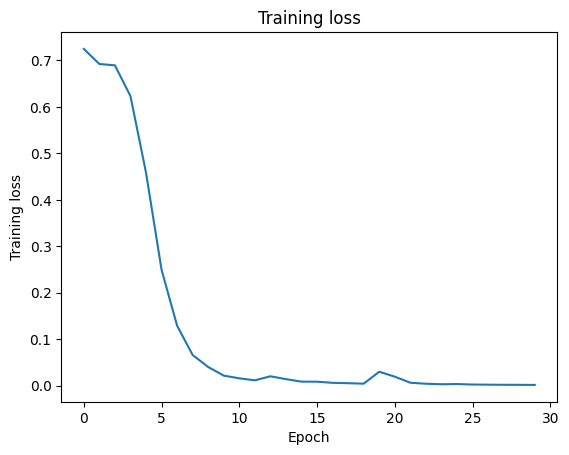

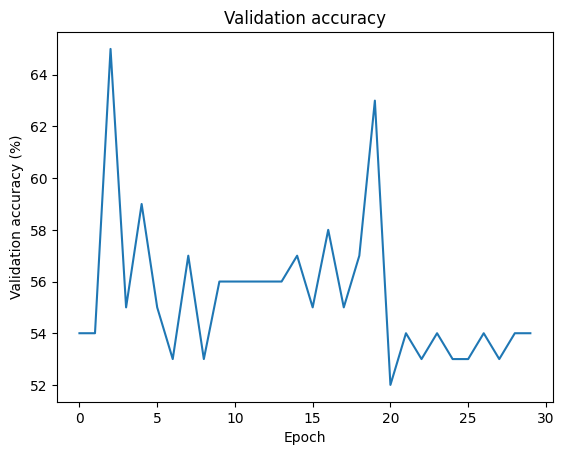

Test accuracy (best val model): 66.00%


In [40]:
# Exercise 4: train the (basic) RNN classifier, plot curves, evaluate on test

# Re-instantiate a fresh model
model = RNNClassifier(
    input_size=input_size,
    emb_size=emb_size_enc,
    hidden_size=hidden_size,
    n_layers=n_layers,
    dropout_rate=dropout_rate,
    bidir=True,
)
model.apply(init_params)

loss_fn = nn.BCEWithLogitsLoss()

model_opt, train_losses, val_accuracies = training_rnnclassif(
    model=model,
    train_dataloader=train_data_loader,
    valid_dataloader=valid_data_loader,
    num_epochs=num_epochs,
    loss_fn=loss_fn,
    learning_rate=learning_rate,
    verbose=True,
)

# Plot training loss
plt.figure()
plt.plot(train_losses)
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.title('Training loss')
plt.show()

# Plot validation accuracy
plt.figure()
plt.plot(val_accuracies)
plt.xlabel('Epoch')
plt.ylabel('Validation accuracy (%)')
plt.title('Validation accuracy')
plt.show()

# Test accuracy (best model)
test_acc = evaluate_rnnclassif(model_opt, test_data_loader)
print(f"Test accuracy (best val model): {test_acc:.2f}%")

**Comment:** The training loss drops to near zero, but validation accuracy stays around 50–60% and is noisy. This indicates overfitting and poor generalization of a basic RNN on this dataset.
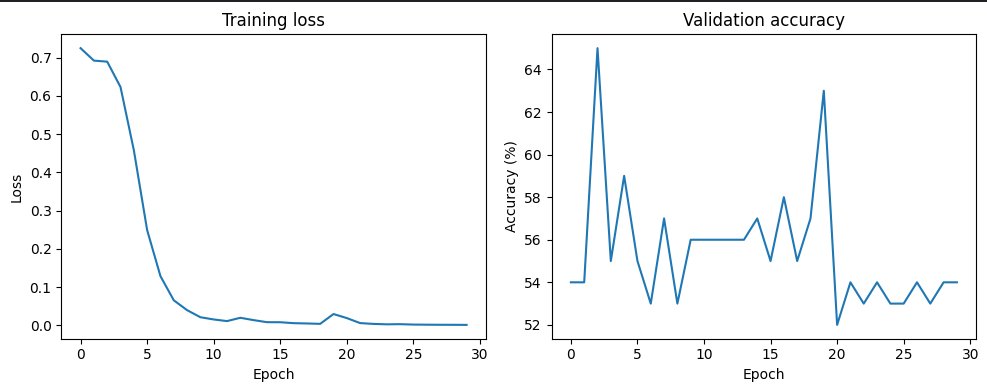

## Alternative networks

To alleviate the problem observed above, we can use the gated variants of recurrent networks (GRU and LSTM) instead of the basic RNN. To that end, we write a `GeneralClassifier` class that is very similar to the `RNNClassifier`, but it takes an additional input argument `net_type` that can be `'rnn'`, `'gru'`, or `'lstm'`. Remember that unlike the basic RNN and GRU, the LSTM outputs an additional cell state, so be careful when implementing the `forward` pass (here the classifier only uses the hidden state, so the cell state can be discarded).

<span style="color:red">**Exercise 5**</span> Write this `GeneralClassifier` class. For each network type (RNN, GRU, LSTM), instanciate and initialize the model, print the number of parameters, train it, and compute the test accuracy. Which one do you recommend to use?

In [41]:
class GeneralClassifier(nn.Module):
    def __init__(self, input_size, emb_size, hidden_size, n_layers, dropout_rate, net_type='rnn', bidir=True):
        super().__init__()

        net_type = net_type.lower()
        assert net_type in {'rnn', 'gru', 'lstm'}, "net_type must be 'rnn', 'gru', or 'lstm'"

        self.net_type = net_type
        self.input_size = input_size
        self.emb_size = emb_size
        self.hidden_size = hidden_size
        self.n_layers = n_layers
        self.dropout_rate = dropout_rate
        self.bidir = bidir
        self.n_directions = 2 if bidir else 1

        self.embedding = nn.Embedding(input_size, emb_size)
        self.dropout = nn.Dropout(dropout_rate)
        rnn_dropout = dropout_rate if n_layers > 1 else 0.0

        if net_type == 'rnn':
            self.recurrent = nn.RNN(
                emb_size, hidden_size, n_layers,
                bidirectional=bidir, dropout=rnn_dropout
            )
        elif net_type == 'gru':
            self.recurrent = nn.GRU(
                emb_size, hidden_size, n_layers,
                bidirectional=bidir, dropout=rnn_dropout
            )
        else:  # lstm
            self.recurrent = nn.LSTM(
                emb_size, hidden_size, n_layers,
                bidirectional=bidir, dropout=rnn_dropout
            )

        self.fc = nn.Linear(hidden_size * n_layers * self.n_directions, 1)

    def forward(self, src):
        emb = self.embedding(src)
        emb = self.dropout(emb)

        if self.net_type == 'lstm':
            _, (hidden, _) = self.recurrent(emb)
        else:
            _, hidden = self.recurrent(emb)

        hidden = hidden.permute(1, 0, 2).contiguous()   # [batch, n_layers*n_dir, hidden]
        hidden = hidden.view(hidden.size(0), -1)
        out = self.fc(hidden)
        return out


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

In [42]:
loss_fn = nn.BCEWithLogitsLoss()

results = {}
for net_type in ['rnn', 'gru', 'lstm']:
    print()
    print('='*60)
    print('Training:', net_type.upper())

    m = GeneralClassifier(
        input_size=input_size,
        emb_size=emb_size_enc,
        hidden_size=hidden_size,
        n_layers=n_layers,
        dropout_rate=dropout_rate,
        net_type=net_type,
        bidir=True,
    )
    m.apply(init_params)

    print('Trainable params:', count_params(m))

    m_opt, tr_losses, val_accs = training_rnnclassif(
        model=m,
        train_dataloader=train_data_loader,
        valid_dataloader=valid_data_loader,
        num_epochs=num_epochs,
        loss_fn=loss_fn,
        learning_rate=learning_rate,
        verbose=False,
    )

    test_acc = evaluate_rnnclassif(m_opt, test_data_loader)
    print(f'Test accuracy: {test_acc:.2f}%')

    results[net_type] = {
        'params': count_params(m),
        'test_acc': test_acc,
        'train_losses': tr_losses,
        'val_accs': val_accs,
    }

print()
print('Summary:')
for k, v in results.items():
    print(f"{k.upper():4s} | params={v['params']} | test_acc={v['test_acc']:.2f}%")


Training: RNN
Trainable params: 537569
Test accuracy: 66.00%

Training: GRU
Trainable params: 558561
Test accuracy: 80.00%

Training: LSTM
Trainable params: 569057
Test accuracy: 81.00%

Summary:
RNN  | params=537569 | test_acc=66.00%
GRU  | params=558561 | test_acc=80.00%
LSTM | params=569057 | test_acc=81.00%


### Visualization

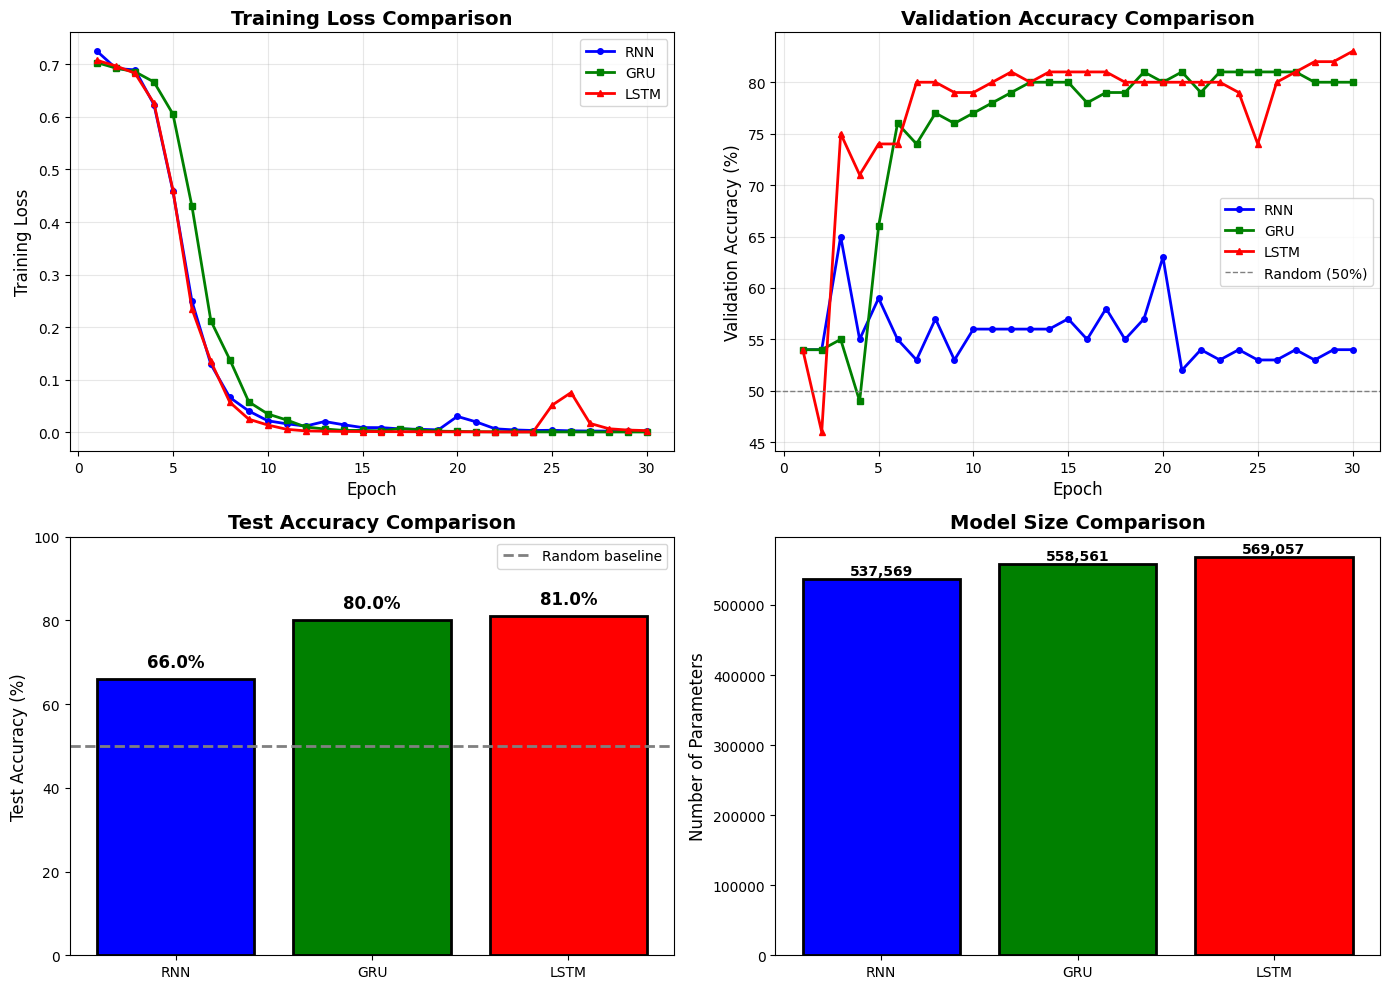

In [43]:
colors = {'rnn': 'blue', 'gru': 'green', 'lstm': 'red'}
markers = {'rnn': 'o', 'gru': 's', 'lstm': '^'}

# All plots in one figure (2x2 grid)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Training Loss Comparison
ax1 = axes[0, 0]
for net_type, result in results.items():
    ax1.plot(range(1, num_epochs+1), result['train_losses'], 
             color=colors[net_type], marker=markers[net_type], 
             markersize=4, linewidth=2, label=net_type.upper())
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Training Loss', fontsize=12)
ax1.set_title('Training Loss Comparison', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Validation Accuracy Comparison
ax2 = axes[0, 1]
for net_type, result in results.items():
    ax2.plot(range(1, num_epochs+1), result['val_accs'],
             color=colors[net_type], marker=markers[net_type],
             markersize=4, linewidth=2, label=net_type.upper())
ax2.axhline(y=50, color='gray', linestyle='--', linewidth=1, label='Random (50%)')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Validation Accuracy (%)', fontsize=12)
ax2.set_title('Validation Accuracy Comparison', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Test Accuracy Bar Chart
ax3 = axes[1, 0]
net_types = list(results.keys())
test_accs = [results[nt]['test_acc'] for nt in net_types]
bars = ax3.bar([nt.upper() for nt in net_types], test_accs, 
               color=[colors[nt] for nt in net_types], edgecolor='black', linewidth=2)
ax3.axhline(y=50, color='gray', linestyle='--', linewidth=2, label='Random baseline')
ax3.set_ylabel('Test Accuracy (%)', fontsize=12)
ax3.set_title('Test Accuracy Comparison', fontsize=14, fontweight='bold')
ax3.set_ylim(0, 100)
for bar, acc in zip(bars, test_accs):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, 
             f'{acc:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=12)
ax3.legend()

# Plot 4: Number of Parameters Bar Chart
ax4 = axes[1, 1]
params = [results[nt]['params'] for nt in net_types]
bars = ax4.bar([nt.upper() for nt in net_types], params,
               color=[colors[nt] for nt in net_types], edgecolor='black', linewidth=2)
ax4.set_ylabel('Number of Parameters', fontsize=12)
ax4.set_title('Model Size Comparison', fontsize=14, fontweight='bold')
for bar, p in zip(bars, params):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000, 
             f'{p:,}', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

### Recommendation

LSTM gives the best accuracy (81%) with only a small increase in parameters compared to GRU. GRU is a close second with fewer parameters, so it’s a good trade‑off if efficiency matters. LSTM is recommended as the preferred model for achieving the best performance.

# Transformers (**for those who finished the rest only!**)

You can try fine-tuning a small transformer classifier on this data as well, to see how it compares!

We can use the HuggingFace `transformers` library for this. We'll need to install it if it isn't already.

# Transformers (**for those who finished the rest only!**)

In [53]:
%pip install transformers evaluate scikit-learn seaborn

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Note: you may need to restart the kernel to use updated packages.


In [54]:
import os
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import evaluate
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Set cache directories
os.environ["HF_HOME"] = os.path.expandvars("$TMPDIR/hf")
os.environ["TRANSFORMERS_CACHE"] = os.path.expandvars("$TMPDIR/hf/transformers")
os.environ["HF_DATASETS_CACHE"] = os.path.expandvars("$TMPDIR/hf/datasets")
os.environ["HF_TOKENIZERS_CACHE"] = os.path.expandvars("$TMPDIR/hf/tokenizers")

# Check GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Using device: cuda
GPU: Tesla P100-PCIE-16GB
GPU Memory: 17.06 GB


# Data Preparation With TRAIN/VAL/TEST Split

In [55]:
model_name = "prajjwal1/bert-tiny"
num_labels = 2

# Load tokenizer and model
tokenizer = AutoTokenizer.from_pretrained(model_name)
transformer_model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=num_labels)

# Count transformer parameters
transformer_params = sum(p.numel() for p in transformer_model.parameters() if p.requires_grad)
print(f"Transformer ({model_name}) parameters: {transformer_params:,}")

def tokenize_batch(batch):
    return tokenizer(
        batch["tweet"],
        padding="max_length",
        truncation=True,
        max_length=128,
    )

# First split: train (80%) vs temp (20%)
splits = dataset.train_test_split(test_size=0.2, seed=42)
train_ds = splits["train"]
temp_ds = splits["test"]

# Second split: val (50%) vs test (50%) from temp
val_test_splits = temp_ds.train_test_split(test_size=0.5, seed=42)
val_ds = val_test_splits["train"]
test_ds = val_test_splits["test"]

print(f"Train size: {len(train_ds)} | Val size: {len(val_ds)} | Test size: {len(test_ds)}")

# Check class distribution
def get_class_distribution(ds):
    labels = ds["label"]
    pos = sum(labels)
    neg = len(labels) - pos
    return pos, neg, pos/len(labels)*100

for name, ds in [("Train", train_ds), ("Val", val_ds), ("Test", test_ds)]:
    pos, neg, pct = get_class_distribution(ds)
    print(f"{name}: Positive={pos}, Negative={neg}, Positive%={pct:.2f}%")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at prajjwal1/bert-tiny and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Transformer (prajjwal1/bert-tiny) parameters: 4,386,178
Train size: 25569 | Val size: 3196 | Test size: 3197
Train: Positive=1782, Negative=23787, Positive%=6.97%
Val: Positive=223, Negative=2973, Positive%=6.98%
Test: Positive=237, Negative=2960, Positive%=7.41%


# Tokenize Datasets


In [56]:
columns_to_remove = [col for col in ["en_ids", "tokens"] if col in train_ds.column_names]

train_ds = train_ds.map(tokenize_batch, batched=True, remove_columns=columns_to_remove)
val_ds = val_ds.map(tokenize_batch, batched=True, remove_columns=columns_to_remove)
test_ds = test_ds.map(tokenize_batch, batched=True, remove_columns=columns_to_remove)

torch_columns = ["input_ids", "attention_mask", "label"]
if "token_type_ids" in train_ds.column_names:
    torch_columns.append("token_type_ids")

train_ds.set_format(type="torch", columns=torch_columns, output_all_columns=True)
val_ds.set_format(type="torch", columns=torch_columns, output_all_columns=True)
test_ds.set_format(type="torch", columns=torch_columns, output_all_columns=True)

print("Sample tokenized data:")
print(train_ds[0])

Map:   0%|          | 0/3196 [00:00<?, ? examples/s]

Map:   0%|          | 0/3197 [00:00<?, ? examples/s]

Sample tokenized data:
{'label': tensor(0), 'input_ids': tensor([  101,  1030,  5310,  1045,  2074,  2387,  9874,  2075,  1001, 26209,
         4095,  5573,  1045,  2245,  2049,  2055,  3376,  3028,  1012,  2053,
         2028,  2064, 17607,  1996,  4676,  1012,  1012,   102,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
       

# Comprehensive Metrics Setup


In [57]:
accuracy_metric = evaluate.load("accuracy")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    
    return {
        "accuracy": accuracy_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision": precision_metric.compute(predictions=preds, references=labels, average="binary")["precision"],
        "recall": recall_metric.compute(predictions=preds, references=labels, average="binary")["recall"],
        "f1": f1_metric.compute(predictions=preds, references=labels, average="binary")["f1"],
    }

# Training Configuration With GPU 

In [58]:
# Determine if GPU is available
use_gpu = torch.cuda.is_available()

training_args = TrainingArguments(
    output_dir=os.path.expandvars("$TMPDIR/transformer_hate_speech"),
    
    # Training hyperparameters
    per_device_train_batch_size=32 if use_gpu else 16,
    per_device_eval_batch_size=64 if use_gpu else 32,
    num_train_epochs=5,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_ratio=0.1,
    
    # Evaluation strategy
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=50,
    
    # Best model selection
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    
    # GPU/CPU settings
    use_cpu=not use_gpu,
    fp16=use_gpu, 
    
    report_to="none",
    seed=42,
)

# Reload model 
transformer_model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=num_labels)

trainer = Trainer(
    model=transformer_model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
)

print(f"Training on: {'GPU (' + torch.cuda.get_device_name(0) + ')' if use_gpu else 'CPU'}")
print(f"Mixed precision (fp16): {use_gpu}")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at prajjwal1/bert-tiny and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Training on: GPU (Tesla P100-PCIE-16GB)
Mixed precision (fp16): True


# Training

In [59]:
print(f"Starting training of {model_name}...")
print(f"Training samples: {len(train_ds)}")
print(f"Validation samples: {len(val_ds)}")
print("="*70)

train_result = trainer.train()

print("\n" + "="*70)
print("Training completed!")
print(f"Total training time: {train_result.metrics['train_runtime']:.2f} seconds")
print(f"Training samples/second: {train_result.metrics['train_samples_per_second']:.2f}")

Starting training of prajjwal1/bert-tiny...
Training samples: 25569
Validation samples: 3196


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.183700,0.169779,0.942115,0.771429,0.242152,0.368601
2,0.137500,0.136147,0.953066,0.721212,0.533632,0.613402
3,0.132300,0.126513,0.958073,0.776398,0.560538,0.651042
4,0.109100,0.123299,0.958073,0.766467,0.573991,0.656410
5,0.108300,0.122849,0.959637,0.790123,0.573991,0.664935



Training completed!
Total training time: 58.07 seconds
Training samples/second: 2201.46


# Extract Training History


In [60]:
log_history = trainer.state.log_history

train_logs = [log for log in log_history if 'loss' in log and 'eval_loss' not in log]
eval_logs = [log for log in log_history if 'eval_loss' in log]

train_steps = [log['step'] for log in train_logs]
train_losses = [log['loss'] for log in train_logs]

eval_epochs = [log['epoch'] for log in eval_logs]
eval_losses = [log['eval_loss'] for log in eval_logs]
eval_accuracies = [log['eval_accuracy'] * 100 for log in eval_logs]
eval_precisions = [log['eval_precision'] * 100 for log in eval_logs]
eval_recalls = [log['eval_recall'] * 100 for log in eval_logs]
eval_f1s = [log['eval_f1'] * 100 for log in eval_logs]

print("Training history extracted successfully!")
print(f"Training steps logged: {len(train_logs)}")
print(f"Evaluation epochs logged: {len(eval_logs)}")

Training history extracted successfully!
Training steps logged: 80
Evaluation epochs logged: 5


# Evaluation On Validation And Test Sets


In [61]:
print("="*70)
print("VALIDATION SET EVALUATION")
print("="*70)
val_results = trainer.evaluate(val_ds)
for key, value in val_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")

print("\n" + "="*70)
print("TEST SET EVALUATION")
print("="*70)
test_results = trainer.evaluate(test_ds)
for key, value in test_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")

VALIDATION SET EVALUATION


eval_loss: 0.1228
eval_accuracy: 0.9596
eval_precision: 0.7901
eval_recall: 0.5740
eval_f1: 0.6649
eval_runtime: 0.3983
eval_samples_per_second: 8023.3260
eval_steps_per_second: 125.5210
epoch: 5.0000

TEST SET EVALUATION
eval_loss: 0.1364
eval_accuracy: 0.9543
eval_precision: 0.7630
eval_recall: 0.5570
eval_f1: 0.6439
eval_runtime: 0.4396
eval_samples_per_second: 7273.1710
eval_steps_per_second: 113.7500
epoch: 5.0000


# Confusion Matrix And Classification Report


In [62]:
test_predictions = trainer.predict(test_ds)
test_preds = test_predictions.predictions.argmax(-1)
test_labels = test_predictions.label_ids

cm = confusion_matrix(test_labels, test_preds)
print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(test_labels, test_preds, target_names=['No Hate Speech', 'Hate Speech']))


Confusion Matrix:
[[2919   41]
 [ 105  132]]

Classification Report:
                precision    recall  f1-score   support

No Hate Speech       0.97      0.99      0.98      2960
   Hate Speech       0.76      0.56      0.64       237

      accuracy                           0.95      3197
     macro avg       0.86      0.77      0.81      3197
  weighted avg       0.95      0.95      0.95      3197



# Visualization 

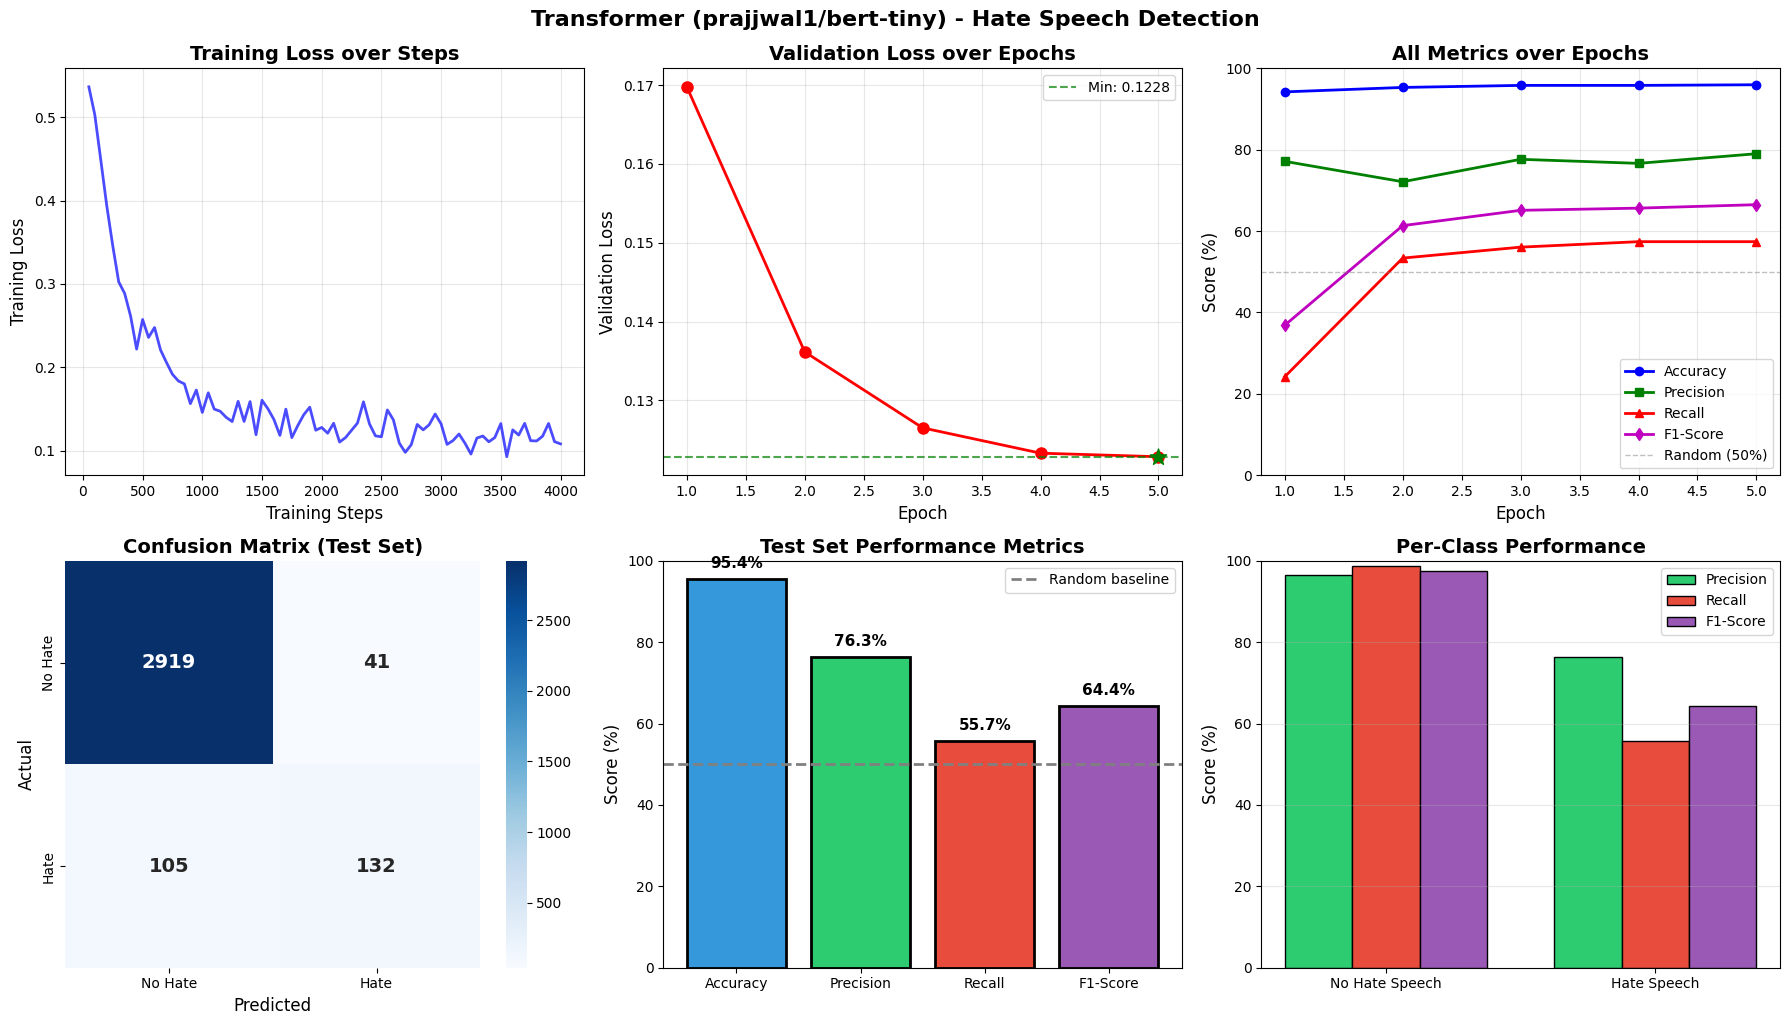

In [63]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Plot 1: Training Loss
ax1 = axes[0, 0]
ax1.plot(train_steps, train_losses, 'b-', linewidth=2, alpha=0.7)
ax1.set_xlabel('Training Steps', fontsize=12)
ax1.set_ylabel('Training Loss', fontsize=12)
ax1.set_title('Training Loss over Steps', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Plot 2: Validation Loss
ax2 = axes[0, 1]
ax2.plot(eval_epochs, eval_losses, 'r-', marker='o', markersize=8, linewidth=2)
min_val_loss = min(eval_losses)
best_epoch_loss = eval_epochs[eval_losses.index(min_val_loss)]
ax2.axhline(y=min_val_loss, color='green', linestyle='--', alpha=0.7, label=f'Min: {min_val_loss:.4f}')
ax2.scatter([best_epoch_loss], [min_val_loss], color='green', s=150, zorder=5, marker='*')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Validation Loss', fontsize=12)
ax2.set_title('Validation Loss over Epochs', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: All Metrics
ax3 = axes[0, 2]
ax3.plot(eval_epochs, eval_accuracies, 'b-', marker='o', markersize=6, linewidth=2, label='Accuracy')
ax3.plot(eval_epochs, eval_precisions, 'g-', marker='s', markersize=6, linewidth=2, label='Precision')
ax3.plot(eval_epochs, eval_recalls, 'r-', marker='^', markersize=6, linewidth=2, label='Recall')
ax3.plot(eval_epochs, eval_f1s, 'm-', marker='d', markersize=6, linewidth=2, label='F1-Score')
ax3.axhline(y=50, color='gray', linestyle='--', linewidth=1, alpha=0.5, label='Random (50%)')
ax3.set_xlabel('Epoch', fontsize=12)
ax3.set_ylabel('Score (%)', fontsize=12)
ax3.set_title('All Metrics over Epochs', fontsize=14, fontweight='bold')
ax3.legend(loc='lower right')
ax3.grid(True, alpha=0.3)
ax3.set_ylim(0, 100)

# Plot 4: Confusion Matrix
ax4 = axes[1, 0]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax4,
            xticklabels=['No Hate', 'Hate'], yticklabels=['No Hate', 'Hate'],
            annot_kws={'size': 14, 'weight': 'bold'})
ax4.set_xlabel('Predicted', fontsize=12)
ax4.set_ylabel('Actual', fontsize=12)
ax4.set_title('Confusion Matrix (Test Set)', fontsize=14, fontweight='bold')

# Plot 5: Test Metrics Bar Chart
ax5 = axes[1, 1]
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
metrics_values = [
    test_results['eval_accuracy'] * 100,
    test_results['eval_precision'] * 100,
    test_results['eval_recall'] * 100,
    test_results['eval_f1'] * 100
]
colors_metrics = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6']
bars = ax5.bar(metrics_names, metrics_values, color=colors_metrics, edgecolor='black', linewidth=2)
ax5.axhline(y=50, color='gray', linestyle='--', linewidth=2, label='Random baseline')
ax5.set_ylabel('Score (%)', fontsize=12)
ax5.set_title('Test Set Performance Metrics', fontsize=14, fontweight='bold')
ax5.set_ylim(0, 100)
for bar, val in zip(bars, metrics_values):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
             f'{val:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)
ax5.legend()

# Plot 6: Per-Class Performance
ax6 = axes[1, 2]
report = classification_report(test_labels, test_preds, output_dict=True)
classes = ['No Hate Speech', 'Hate Speech']
x_pos = np.arange(len(classes))
width = 0.25

precision_vals = [report['0']['precision']*100, report['1']['precision']*100]
recall_vals = [report['0']['recall']*100, report['1']['recall']*100]
f1_vals = [report['0']['f1-score']*100, report['1']['f1-score']*100]

ax6.bar(x_pos - width, precision_vals, width, label='Precision', color='#2ecc71', edgecolor='black')
ax6.bar(x_pos, recall_vals, width, label='Recall', color='#e74c3c', edgecolor='black')
ax6.bar(x_pos + width, f1_vals, width, label='F1-Score', color='#9b59b6', edgecolor='black')
ax6.set_ylabel('Score (%)', fontsize=12)
ax6.set_title('Per-Class Performance', fontsize=14, fontweight='bold')
ax6.set_xticks(x_pos)
ax6.set_xticklabels(classes)
ax6.legend()
ax6.set_ylim(0, 100)
ax6.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.suptitle(f'Transformer ({model_name}) - Hate Speech Detection', fontsize=16, fontweight='bold', y=1.02)
plt.show()

# Comparison

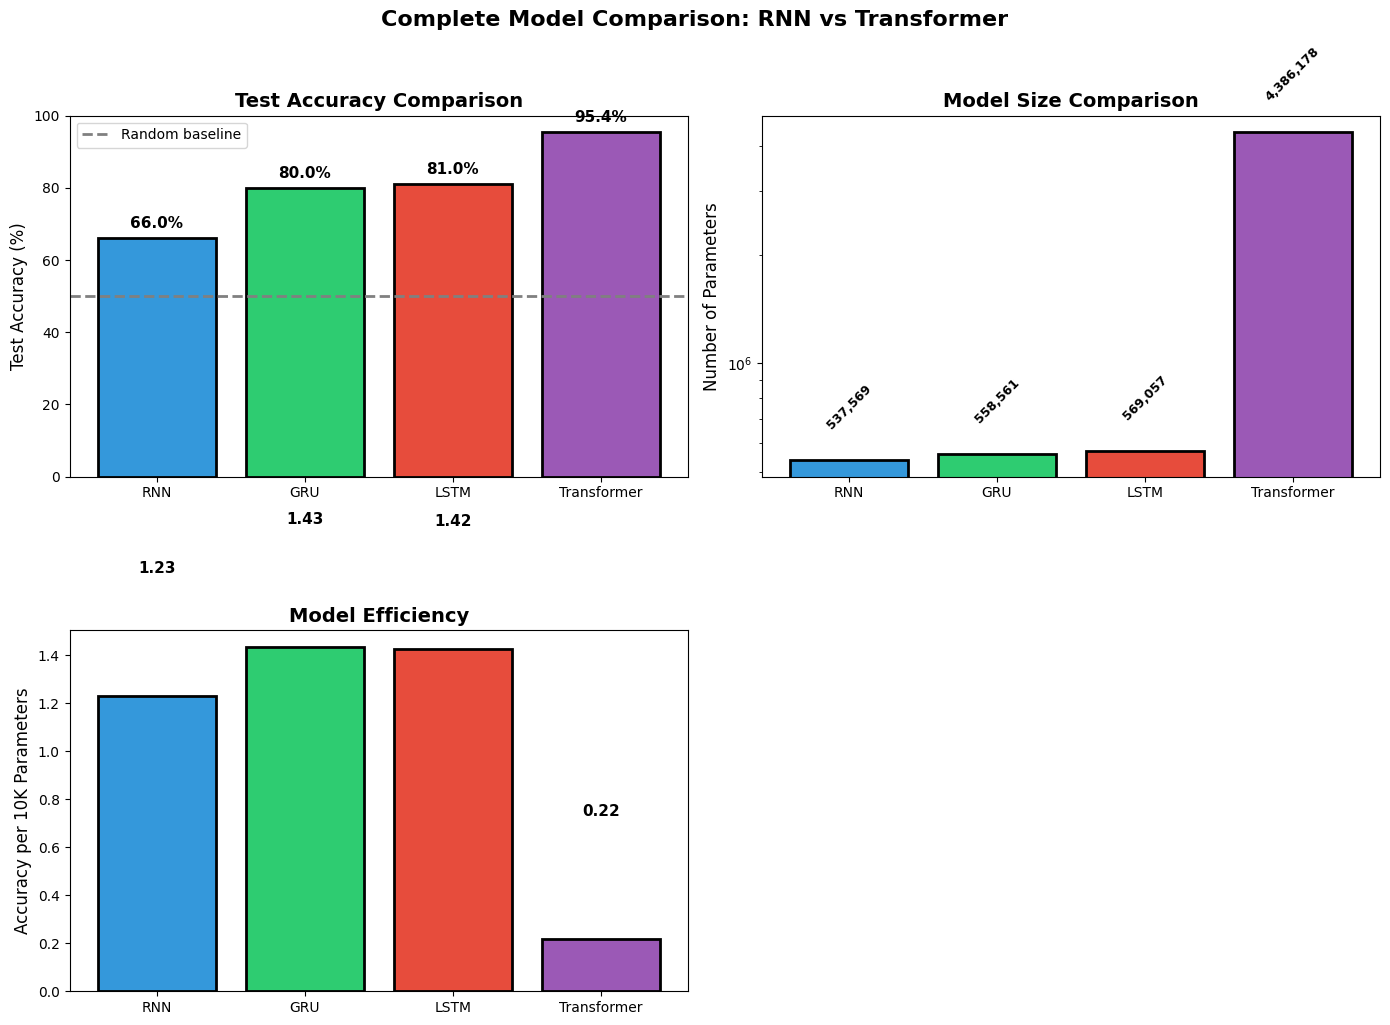

In [72]:
# Store transformer results
transformer_results = {
    'params': transformer_params,
    'test_acc': test_results['eval_accuracy'] * 100,
    'test_precision': test_results['eval_precision'] * 100,
    'test_recall': test_results['eval_recall'] * 100,
    'test_f1': test_results['eval_f1'] * 100,
    'test_loss': test_results['eval_loss'],
}

# Combined visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

all_models = ['RNN', 'GRU', 'LSTM', 'Transformer']
all_colors = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6']

# Get results from previous experiments
rnn_acc = results['rnn']['test_acc']
gru_acc = results['gru']['test_acc']
lstm_acc = results['lstm']['test_acc']
trans_acc = transformer_results['test_acc']

rnn_params = results['rnn']['params']
gru_params = results['gru']['params']
lstm_params = results['lstm']['params']
trans_params = transformer_results['params']

all_accs = [rnn_acc, gru_acc, lstm_acc, trans_acc]
all_params = [rnn_params, gru_params, lstm_params, trans_params]

# Plot 1: Test Accuracy Comparison
ax1 = axes[0, 0]
bars = ax1.bar(all_models, all_accs, color=all_colors, edgecolor='black', linewidth=2)
ax1.axhline(y=50, color='gray', linestyle='--', linewidth=2, label='Random baseline')
ax1.set_ylabel('Test Accuracy (%)', fontsize=12)
ax1.set_title('Test Accuracy Comparison', fontsize=14, fontweight='bold')
ax1.set_ylim(0, 100)
for bar, acc in zip(bars, all_accs):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
             f'{acc:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)
ax1.legend()

# Plot 2: Parameters Comparison (Log Scale)
ax2 = axes[0, 1]
bars = ax2.bar(all_models, all_params, color=all_colors, edgecolor='black', linewidth=2)
ax2.set_ylabel('Number of Parameters', fontsize=12)
ax2.set_title('Model Size Comparison', fontsize=14, fontweight='bold')
ax2.set_yscale('log')
for bar, p in zip(bars, all_params):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.2,
             f'{p:,}', ha='center', va='bottom', fontweight='bold', fontsize=9, rotation=45)

# Plot 3: Efficiency (Accuracy per 10K params)
ax3 = axes[1, 0]
efficiency = [acc / (p / 10000) for acc, p in zip(all_accs, all_params)]
bars = ax3.bar(all_models, efficiency, color=all_colors, edgecolor='black', linewidth=2)
ax3.set_ylabel('Accuracy per 10K Parameters', fontsize=12)
ax3.set_title('Model Efficiency', fontsize=14, fontweight='bold')
for bar, eff in zip(bars, efficiency):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{eff:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=11)


fig.delaxes(axes[1, 1])
plt.tight_layout()
plt.suptitle('Complete Model Comparison: RNN vs Transformer', fontsize=16, fontweight='bold', y=1.02)
plt.show()

# Final Comprehensive Summary


In [73]:
print("\n" + "="*110)
print("COMPLETE MODEL COMPARISON SUMMARY")
print("="*110)
print(f"{'Model':<15} {'Parameters':>15} {'Test Acc':>12} {'Test F1':>12} {'Efficiency':>15} {'Device':>10}")
print("-"*110)

# RNN models
for net_type in ['rnn', 'gru', 'lstm']:
    r = results[net_type]
    eff = r['test_acc'] / (r['params'] / 10000)
    print(f"{net_type.upper():<15} {r['params']:>15,} {r['test_acc']:>11.2f}% {'N/A':>12} {eff:>14.2f} {'CPU':>10}")

# Transformer
eff_trans = transformer_results['test_acc'] / (transformer_params / 10000)
device_str = 'GPU' if torch.cuda.is_available() else 'CPU'
print(f"{'Transformer':<15} {transformer_params:>15,} {transformer_results['test_acc']:>11.2f}% {transformer_results['test_f1']:>11.2f}% {eff_trans:>14.2f} {device_str:>10}")

print("-"*110)

# Find best model
all_results = {**{k: v['test_acc'] for k, v in results.items()}, 'transformer': transformer_results['test_acc']}
best_model = max(all_results, key=all_results.get)
print(f"\nBest performing model: {best_model.upper()} with {all_results[best_model]:.2f}% accuracy")

# Most efficient model
all_eff = {
    'rnn': results['rnn']['test_acc'] / (results['rnn']['params'] / 10000),
    'gru': results['gru']['test_acc'] / (results['gru']['params'] / 10000),
    'lstm': results['lstm']['test_acc'] / (results['lstm']['params'] / 10000),
    'transformer': transformer_results['test_acc'] / (transformer_params / 10000),
}
print("\n" + "="*110)
print("TRANSFORMER DETAILED METRICS")
print("="*110)
print(f"Model: {model_name}")
print(f"Parameters: {transformer_params:,}")
print(f"Test Accuracy: {transformer_results['test_acc']:.2f}%")
print(f"Test Precision: {transformer_results['test_precision']:.2f}%")
print(f"Test Recall: {transformer_results['test_recall']:.2f}%")
print(f"Test F1-Score: {transformer_results['test_f1']:.2f}%")
print(f"Test Loss: {transformer_results['test_loss']:.4f}")
print(f"Training Device: {device_str}")
print("="*110)


COMPLETE MODEL COMPARISON SUMMARY
Model                Parameters     Test Acc      Test F1      Efficiency     Device
--------------------------------------------------------------------------------------------------------------
RNN                     537,569       66.00%          N/A           1.23        CPU
GRU                     558,561       80.00%          N/A           1.43        CPU
LSTM                    569,057       81.00%          N/A           1.42        CPU
Transformer           4,386,178       95.43%       64.39%           0.22        GPU
--------------------------------------------------------------------------------------------------------------

Best performing model: TRANSFORMER with 95.43% accuracy

TRANSFORMER DETAILED METRICS
Model: prajjwal1/bert-tiny
Parameters: 4,386,178
Test Accuracy: 95.43%
Test Precision: 76.30%
Test Recall: 55.70%
Test F1-Score: 64.39%
Test Loss: 0.1364
Training Device: GPU


## Analyse des résultats

Sur le test, le Transformer atteint 95.43% d’accuracy et loss 0.1364, nettement meilleur que RNN/GRU/LSTM. Cela s’explique par le pré-entraînement: le modèle a déjà appris des représentations linguistiques utiles avant le fine-tuning.

Cependant, le jeu de données est déséquilibré, beaucoup plus de *No Hate Speech* que de *Hate Speech*. La matrice de confusion montre :
- **FP = 41** : peu de fausses alertes
- **FN = 105** : beaucoup de cas de haine manqués

Les métriques pour *Hate Speech* confirment ce comportement :
- **Precision = 76.30%** : quand il prédit “hate”, il a souvent raison
- **Recall = 55.70%** il ne détecte qu’un peu plus de la moitié des cas
- **F1 = 64.39%**

**Conclusion** : excellent score global, mais le modèle reste conservateur et rate encore une partie importante de la classe minoritaire.